
<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA

Tugas 3 (Membuat Recipe) </strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>PIARA</span><span>(H061241046)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>




# RECIPE GEOFISIKA: PEMERIKSAAN KUALITAS DAN VISUALISASI DATA RESISTIVITAS SEMU


---

## Recipe ID: GEO-QC-ERT-001

**Bidang:** Geofisika dekat permukaan (*near-surface geophysics*)  
**Topik:** Pemeriksaan kualitas (*quality control/QC*), pembersihan, dan visualisasi data resistivitas semu pada lintasan geolistrik.

> **Catatan:** Jika data pengukuran lapangan belum tersedia, notebook menggunakan data simulasi agar seluruh tahapan dapat dicoba. Data simulasi bukan hasil pengukuran nyata dan tidak boleh digunakan untuk menyimpulkan kondisi bawah permukaan suatu lokasi.



## 1. Problem — Permasalahan

Data geolistrik yang dikumpulkan di lapangan perlu diperiksa sebelum digunakan untuk analisis atau interpretasi. Kesalahan seperti nilai kosong, pengukuran ganda, koordinat yang tidak sesuai, atau nilai resistivitas yang tidak masuk akal dapat memengaruhi hasil visualisasi dan kesimpulan.

Tujuan recipe ini adalah:

1. Membuat atau membaca tabel data resistivitas semu.
2. Memeriksa kelengkapan kolom dan kualitas data.
3. Mengidentifikasi nilai kosong, data duplikat, dan nilai resistivitas tidak valid.
4. Membersihkan data berdasarkan aturan yang dinyatakan secara jelas.
5. Membuat grafik resistivitas semu terhadap posisi sepanjang lintasan.
6. Menyimpan data hasil pemeriksaan dan ringkasan QC ke file CSV.



## 2. Minimal Theory — Teori Singkat

Resistivitas semu (\(\rho_a\)) merupakan nilai resistivitas yang dihitung dari pengukuran geolistrik berdasarkan konfigurasi elektroda yang digunakan. Nilai ini masih dipengaruhi oleh susunan lapisan bawah permukaan dan konfigurasi pengukuran, sehingga tidak langsung sama dengan resistivitas sebenarnya dari satu lapisan batuan.

Pada tahap pemeriksaan kualitas, data dapat ditinjau melalui beberapa aspek:

- **Kelengkapan:** apakah kolom penting dan nilai pengukuran tersedia.
- **Duplikasi:** apakah ada catatan pengukuran yang tercatat lebih dari satu kali.
- **Validitas nilai:** apakah nilai resistivitas semu positif dan dapat diproses.
- **Konsistensi posisi:** apakah posisi pengukuran tercatat sebagai angka dan berada pada rentang yang diharapkan.

Pembersihan data tidak boleh dilakukan secara sembarangan. Setiap nilai yang dihapus harus berdasarkan aturan yang jelas, dan data asli sebaiknya tetap disimpan.



## 3. Persiapan — Library yang Digunakan

Kode berikut menggunakan NumPy untuk perhitungan numerik, pandas untuk pengelolaan tabel, dan Matplotlib untuk membuat grafik. Seluruh pustaka tersebut umum digunakan dalam analisis data geosains dengan Python.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Library berhasil diimpor.")


Library berhasil diimpor.



## 4. Prompt — Instruksi Analisis untuk AI

Gunakan instruksi berikut sebagai panduan ketika meminta AI membantu proses pemeriksaan data:

> Periksa tabel pengukuran resistivitas semu pada lintasan geolistrik. Pastikan kolom posisi dan resistivitas tersedia, hitung jumlah nilai kosong, identifikasi data duplikat dan nilai resistivitas yang tidak valid, lalu bersihkan data menggunakan aturan yang transparan. Buat grafik sebelum dan sesudah pembersihan serta ekspor hasilnya ke CSV. Jangan mengarang hasil pengukuran. Jika data simulasi digunakan, nyatakan secara jelas bahwa hasilnya hanya demonstrasi alur komputasi.



## 5. Code — Pengaturan Sumber Data

Pilih sumber data melalui variabel `USE_SIMULATED_DATA`.

- `True`: membuat data simulasi yang dapat langsung dijalankan.
- `False`: membaca file `data_resistivitas.csv` dari folder kerja notebook.

Untuk data asli, CSV perlu memiliki kolom `posisi_m` dan `resistivitas_semu_ohm_m`. Kolom posisi menunjukkan jarak sepanjang lintasan dalam meter, sedangkan kolom resistivitas semu menggunakan satuan ohm meter (\(\Omega\,m\)).


In [2]:

# Pilih True untuk mencoba notebook dengan data simulasi.
# Ubah menjadi False jika ingin membaca file pengukuran sendiri.
USE_SIMULATED_DATA = True

if USE_SIMULATED_DATA:
    # Membuat data simulasi dengan variasi resistivitas sepanjang lintasan.
    rng = np.random.default_rng(42)
    posisi = np.arange(0, 101, 5, dtype=float)
    rho = 80 + 25 * np.sin(posisi / 15) + rng.normal(0, 5, len(posisi))

    df_asli = pd.DataFrame({
        "posisi_m": posisi,
        "resistivitas_semu_ohm_m": rho
    })

    # Memasukkan satu nilai kosong untuk contoh pemeriksaan kualitas.
    df_asli.loc[5, "resistivitas_semu_ohm_m"] = np.nan

    # Menambahkan satu baris duplikat sebagai contoh data ganda.
    df_asli = pd.concat([df_asli, df_asli.iloc[[3]]], ignore_index=True)

    # Menyimpan tabel simulasi awal agar data sumber dapat diperiksa kembali.
    df_asli.to_csv("data_resistivitas_simulasi_awal.csv", index=False)
else:
    # File CSV harus berada di folder kerja notebook.
    df_asli = pd.read_csv("data_resistivitas.csv")

print("Sumber data:", "simulasi" if USE_SIMULATED_DATA else "file pengukuran")
print("Ukuran data awal:", df_asli.shape)
display(df_asli.head())


Sumber data: simulasi
Ukuran data awal: (22, 2)


,posisi_m,resistivitas_semu_ohm_m
0,0.0,81.523585
1,5.0,82.979947
2,10.0,99.211501
3,15.0,105.739598
4,20.0,94.543272



## 6. Code — Pemeriksaan Dasar Data

Bagian ini memeriksa kolom wajib, tipe data, nilai kosong, dan jumlah baris duplikat. Pemeriksaan dilakukan sebelum pembersihan agar kondisi data awal tetap terdokumentasi.


In [3]:

# Pastikan kolom wajib tersedia.
required_columns = ["posisi_m", "resistivitas_semu_ohm_m"]
missing_columns = [col for col in required_columns if col not in df_asli.columns]

if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

# Gunakan hanya kolom yang dibutuhkan dan ubah nilainya menjadi numerik.
df = df_asli[required_columns].copy()
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Jumlah baris awal:", len(df))
print("\nJumlah nilai kosong per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", int(df.duplicated().sum()))
print("\nRingkasan statistik awal:")
display(df.describe())


Jumlah baris awal: 22

Jumlah nilai kosong per kolom:
posisi_m                   0
resistivitas_semu_ohm_m    1
dtype: int64

Jumlah baris duplikat: 1

Ringkasan statistik awal:


,posisi_m,resistivitas_semu_ohm_m
count,22.000000,21.000000
mean,48.409091,80.629598
std,31.182503,16.865263
min,0.000000,51.730431
25%,21.250000,62.410844
50%,47.500000,81.003546
75%,73.750000,94.543272
max,100.000000,105.739598



## 7. Code — Pembersihan Data

Aturan pembersihan pada contoh ini adalah:

1. Menghapus baris yang nilai posisi atau resistivitas semunya kosong/tidak numerik.
2. Menghapus baris duplikat yang identik.
3. Menghapus nilai resistivitas semu yang kurang dari atau sama dengan nol.

Aturan tersebut merupakan contoh QC dasar. Untuk data lapangan, batas nilai dan keputusan penghapusan perlu disesuaikan dengan instrumen, konfigurasi, catatan lapangan, serta standar pengolahan yang digunakan.


In [4]:

# Salin data agar tabel awal tidak berubah.
df_bersih = df.copy()

# Hapus baris dengan nilai kosong atau nilai yang gagal dikonversi menjadi angka.
df_bersih = df_bersih.dropna(subset=required_columns)

# Hapus catatan yang benar-benar duplikat.
df_bersih = df_bersih.drop_duplicates()

# Resistivitas semu harus bernilai positif untuk contoh ini.
df_bersih = df_bersih[df_bersih["resistivitas_semu_ohm_m"] > 0]

# Urutkan data berdasarkan posisi sepanjang lintasan.
df_bersih = df_bersih.sort_values("posisi_m").reset_index(drop=True)

print("Jumlah baris sebelum QC:", len(df))
print("Jumlah baris sesudah QC:", len(df_bersih))
print("Jumlah baris yang tidak dipakai:", len(df) - len(df_bersih))
display(df_bersih.head())


Jumlah baris sebelum QC: 22
Jumlah baris sesudah QC: 20
Jumlah baris yang tidak dipakai: 2


,posisi_m,resistivitas_semu_ohm_m
0,0.0,81.523585
1,5.0,82.979947
2,10.0,99.211501
3,15.0,105.739598
4,20.0,94.543272



## 8. Code — Visualisasi Sebelum dan Sesudah QC

Grafik pertama menunjukkan data sebelum pembersihan, sedangkan grafik kedua menunjukkan data setelah pembersihan. Grafik ini membantu melihat bagaimana pemeriksaan kualitas memengaruhi data yang akan dianalisis.


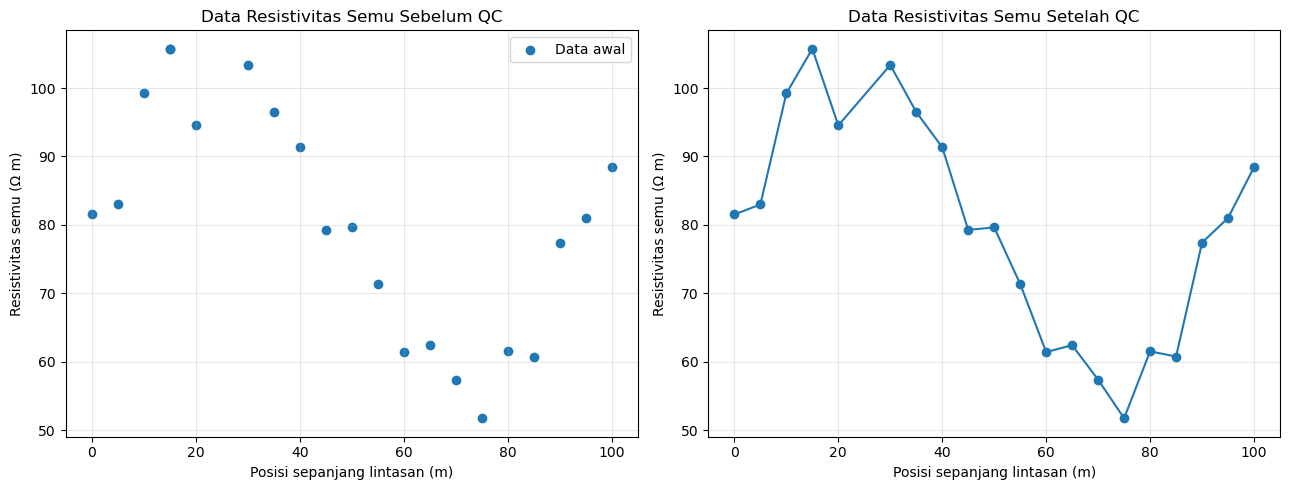

In [8]:

# Membuat grafik sebelum dan sesudah Quality Control (QC)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Urutkan data awal berdasarkan posisi untuk menghindari garis yang melompat.
df_sebelum_plot = df.sort_values("posisi_m")

# Grafik sebelum QC: gunakan titik agar data duplikat lebih mudah dikenali.
axes[0].scatter(
    df_sebelum_plot["posisi_m"],
    df_sebelum_plot["resistivitas_semu_ohm_m"],
    label="Data awal",
    marker="o"
)
axes[0].set_title("Data Resistivitas Semu Sebelum QC")
axes[0].set_xlabel("Posisi sepanjang lintasan (m)")
axes[0].set_ylabel("Resistivitas semu (Ω m)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Grafik sesudah QC: data sudah dibersihkan dan diurutkan.
axes[1].plot(
    df_bersih["posisi_m"],
    df_bersih["resistivitas_semu_ohm_m"],
    marker="o",
    linestyle="-"
)
axes[1].set_title("Data Resistivitas Semu Setelah QC")
axes[1].set_xlabel("Posisi sepanjang lintasan (m)")
axes[1].set_ylabel("Resistivitas semu (Ω m)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## 9. Code — Ringkasan Hasil QC

Ringkasan ini mencatat jumlah baris awal, jumlah baris yang dipertahankan, jumlah baris yang tidak digunakan, serta rentang nilai resistivitas semu setelah pembersihan. Angka yang dihasilkan berasal dari data yang sedang digunakan, sehingga hasilnya akan berubah jika file data diganti.


In [6]:

ringkasan_qc = pd.DataFrame([{
    "jenis_data": "simulasi" if USE_SIMULATED_DATA else "pengukuran",
    "jumlah_baris_awal": int(len(df)),
    "jumlah_baris_setelah_qc": int(len(df_bersih)),
    "jumlah_baris_tidak_digunakan": int(len(df) - len(df_bersih)),
    "jumlah_nilai_kosong_awal": int(df.isna().any(axis=1).sum()),
    "jumlah_duplikat_awal": int(df.duplicated().sum()),
    "resistivitas_min_ohm_m": float(df_bersih["resistivitas_semu_ohm_m"].min()),
    "resistivitas_maks_ohm_m": float(df_bersih["resistivitas_semu_ohm_m"].max()),
    "resistivitas_rata_rata_ohm_m": float(df_bersih["resistivitas_semu_ohm_m"].mean())
}])

display(ringkasan_qc)


,jenis_data,jumlah_baris_awal,jumlah_baris_setelah_qc,jumlah_baris_tidak_digunakan,jumlah_nilai_kosong_awal,jumlah_duplikat_awal,resistivitas_min_ohm_m,resistivitas_maks_ohm_m,resistivitas_rata_rata_ohm_m
0,simulasi,22,20,2,1,1,51.730431,105.739598,79.374098



## 10. Code — Menyimpan Hasil ke CSV

Data yang telah dibersihkan dan ringkasan QC disimpan sebagai file CSV di folder kerja notebook. File data awal juga tetap tersedia jika sumbernya dibuat melalui simulasi.


In [7]:

# Buat folder keluaran jika belum tersedia.
output_dir = Path("hasil_recipe_geofisika")
output_dir.mkdir(exist_ok=True)

# Simpan data bersih dan ringkasan pemeriksaan kualitas.
file_data_bersih = output_dir / "data_resistivitas_setelah_qc.csv"
file_ringkasan = output_dir / "ringkasan_qc_resistivitas.csv"

df_bersih.to_csv(file_data_bersih, index=False)
ringkasan_qc.to_csv(file_ringkasan, index=False)

print("File berhasil disimpan:")
print("-", file_data_bersih)
print("-", file_ringkasan)


File berhasil disimpan:
- hasil_recipe_geofisika\data_resistivitas_setelah_qc.csv
- hasil_recipe_geofisika\ringkasan_qc_resistivitas.csv



## 11. Result — Hasil dan Interpretasi

Setelah seluruh sel dijalankan, perhatikan:

- Jumlah baris dan nilai kosong pada data awal.
- Jumlah data duplikat yang teridentifikasi.
- Jumlah baris yang dipertahankan setelah QC.
- Perubahan tampilan grafik sebelum dan sesudah pembersihan.
- Rentang resistivitas semu pada ringkasan QC.

**Interpretasi batasan:** pemeriksaan kualitas hanya memastikan data memenuhi aturan dasar yang telah ditentukan. Grafik resistivitas semu terhadap posisi bukan penampang inversi geolistrik dan tidak cukup untuk menentukan jenis batuan, kedalaman lapisan, atau potensi mineralisasi. Interpretasi bawah permukaan memerlukan tahapan pengolahan geofisika yang sesuai dan informasi pendukung.

Jika menggunakan data simulasi, semua hasil hanya menunjukkan contoh alur kerja Python, bukan hasil survei lapangan.



## 12. Optional Check — Checklist Kualitas

Gunakan daftar periksa berikut sebelum memakai hasil dalam laporan:

- [ ] Kolom posisi dan resistivitas semu tersedia.
- [ ] Nilai kosong dan data duplikat telah diperiksa.
- [ ] Aturan pembersihan dijelaskan dengan jelas.
- [ ] Data awal disimpan agar hasil QC dapat ditelusuri.
- [ ] Grafik memiliki judul, label sumbu, dan satuan.
- [ ] Data simulasi tidak ditulis sebagai hasil pengukuran lapangan.
- [ ] Interpretasi tidak melebihi informasi yang dapat diberikan oleh data.

## 13. Penutup

Recipe ini memperlihatkan tahapan dasar pemeriksaan kualitas data geolistrik menggunakan Python, mulai dari membaca data, memeriksa kesalahan umum, membersihkan data, membuat visualisasi, hingga mengekspor hasil. Tahapan QC yang baik membantu menjaga keterlacakan dan mengurangi risiko kesalahan sebelum data digunakan pada analisis geofisika berikutnya.
